# Análise Exploratória de Dados — Pinguins do Arquipélago Palmer

**Domínio:** características físicas de pinguins.

**Objetivo:** conhecer a qualidade e a distribuição dos dados, comparar as espécies e investigar como as medidas corporais se relacionam. A base tratada será usada no dashboard de correlação e distribuição.

**Perguntas:** pinguins com nadadeiras mais longas tendem a ter maior massa? Essa relação muda entre espécies? Como a massa corporal se distribui em cada espécie?

**Escolha da base:** Palmer Penguins tem quatro medidas quantitativas, categorias e ausências reais. Permite aplicar histogramas, boxplots, IQR, correlação e filtros numéricos. A versão usada é `penguins`, uma tabela simplificada com 8 colunas, e não `penguins_raw`, que possui 17.

**Fonte:** [Horst, Hill e Gorman — palmerpenguins](https://allisonhorst.github.io/palmerpenguins/), dados coletados por Kristen Gorman e Palmer Station LTER, entre 2007 e 2009. Dados sob licença CC0. [CSV do projeto](https://github.com/allisonhorst/palmerpenguins/blob/main/inst/extdata/penguins.csv). Consulta em 22/10/2026.

**Contexto da atividade:** esta versão segue as seções do notebook de cogumelos enviado e os requisitos da Aula 21. O enunciado completo da atividade anterior não foi disponibilizado. A troca de dataset foi alinhada com a professora, conforme informado pelo estudante, e deve ser informada na entrega.

## Declaração de uso de IA

ChatGPT/Codex foi utilizado na escolha da base, elaboração do código, redação das interpretações e planejamento do dashboard. Os resultados foram calculados pela execução das células. O estudante deve revisar as análises e registrar na declaração da disciplina o que aceitou, modificou ou rejeitou. Não se declara aqui uma revisão humana que ainda não ocorreu.

## 1. Bibliotecas e carregamento dos dados

Execute as células na ordem. Na pasta do projeto, instale `requirements.txt` e selecione o ambiente Python no Jupyter ou VS Code. O CSV local permite executar a análise sem conexão. Se estiver executando somente o notebook em outra pasta ou no Colab, o código baixa a fonte pública e cria as pastas necessárias.

In [1]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 13})
pd.set_option("display.max_columns", 12)
PALETA = {"Adelie": "#306b91", "Chinstrap": "#c27432", "Gentoo": "#5c8260"}
NUM = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
CAT = ["species", "island", "sex"]
ROTULOS = {
    "bill_length_mm": "Comprimento do bico (mm)",
    "bill_depth_mm": "Profundidade do bico (mm)",
    "flipper_length_mm": "Comprimento da nadadeira (mm)",
    "body_mass_g": "Massa corporal (g)",
}
atual = Path.cwd().resolve()
ROOT = next((p for p in [atual, *atual.parents]
             if (p / "requirements.txt").exists() and (p / "notebooks").exists()), atual)
RAW = ROOT / "data/raw/penguins.csv"
CLEAN = ROOT / "data/clean/penguins.csv"
FIG = ROOT / "reports/figures"
for pasta in [RAW.parent, CLEAN.parent, FIG]:
    pasta.mkdir(parents=True, exist_ok=True)
URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/refs/heads/main/inst/extdata/penguins.csv"
if not RAW.exists():
    with urlopen(URL, timeout=30) as resposta:
        RAW.write_bytes(resposta.read())
df_original = pd.read_csv(RAW, na_values=["NA"], keep_default_na=True)
df_antes = df_original.copy(deep=True)
print("Dimensão original:", df_original.shape)
display(df_original.head())

def mostrar_figura(fig, nome):
    fig.tight_layout()
    fig.savefig(FIG / nome, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Dimensão original: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [2]:
SHA_ESPERADO = "f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93"
sha_atual = hashlib.sha256(RAW.read_bytes().replace(b"\r\n", b"\n")).hexdigest()
if sha_atual != SHA_ESPERADO:
    raise ValueError("A fonte mudou. Confira a nova versão antes de reproduzir esta análise.")
print("CSV original conferido por SHA-256:", sha_atual)

CSV original conferido por SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93


## 2. Princípio estrutural

Cada linha representa um registro de pinguim. `species`, `island` e `sex` são categorias. As quatro medidas físicas são quantitativas. `year` indica o ano da coleta; será tratado como período, sem entrar automaticamente na matriz de correlação.

| Coluna | Significado | Tipo analítico |
|---|---|---|
| species | Espécie | Qualitativa nominal |
| island | Ilha | Qualitativa nominal |
| bill_length_mm | Comprimento do bico, mm | Quantitativa contínua |
| bill_depth_mm | Profundidade do bico, mm | Quantitativa contínua |
| flipper_length_mm | Comprimento da nadadeira, mm | Medida quantitativa registrada em inteiros |
| body_mass_g | Massa corporal, g | Medida quantitativa registrada em inteiros |
| sex | Sexo do animal | Qualitativa nominal |
| year | Ano da coleta | Temporal |

In [3]:
estrutura = pd.DataFrame({
    "tipo_no_pandas": df_original.dtypes.astype(str),
    "valores_unicos": df_original.nunique(dropna=True),
    "ausentes": df_original.isna().sum(),
    "ausentes_pct": df_original.isna().mean().mul(100),
})
display(estrutura.round(2))
print("Duplicatas exatas:", df_original.duplicated().sum())
display(df_original.loc[df_original.isna().any(axis=1)])
print("Valores não positivos nas medidas:", (df_original[NUM] <= 0).sum().to_dict())

,tipo_no_pandas,valores_unicos,ausentes,ausentes_pct
species,object,3,0,0.00
island,object,3,0,0.00
bill_length_mm,float64,164,2,0.58
bill_depth_mm,float64,80,2,0.58
flipper_length_mm,float64,55,2,0.58
body_mass_g,float64,94,2,0.58
sex,object,2,11,3.20
year,int64,3,0,0.00


Duplicatas exatas: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


Valores não positivos nas medidas: {'bill_length_mm': 0, 'bill_depth_mm': 0, 'flipper_length_mm': 0, 'body_mass_g': 0}


**Conclusão:** a fonte contém 344 registros e 8 colunas, sem duplicatas exatas. Duas linhas não possuem nenhuma das quatro medidas físicas. A coluna `sex` tem 11 ausências, incluindo essas duas linhas. Não foram encontradas medidas menores ou iguais a zero. Ausência não significa zero, e não é possível afirmar apenas com esta tabela que os dados faltaram de forma aleatória.

## 3. Princípio distribucional

### Medidas de tendência central e dispersão

As estatísticas iniciais usam os valores observados de cada coluna. O número de observações válidas aparece em `n`. Para medidas contínuas, todas as modas empatadas são exibidas; a moda pode depender do arredondamento do instrumento.

In [4]:
def resumo_numerico(dados):
    t = dados[NUM].agg(["count", "mean", "median", "std", "var", "min", "max"]).T
    t.columns = ["n", "media", "mediana", "desvio_padrao", "variancia", "minimo", "maximo"]
    t["q1"] = dados[NUM].quantile(.25)
    t["q3"] = dados[NUM].quantile(.75)
    t["iqr"] = t["q3"] - t["q1"]
    t["amplitude"] = t["maximo"] - t["minimo"]
    t["cv_pct"] = 100 * t["desvio_padrao"] / t["media"]
    return t

resumo_antes = resumo_numerico(df_antes)
display(resumo_antes.round(3))
display(pd.DataFrame({"modas": {c: df_antes[c].mode().tolist() for c in NUM}}))

,n,media,mediana,desvio_padrao,variancia,minimo,maximo,q1,q3,iqr,amplitude,cv_pct
bill_length_mm,342.0,43.922,44.45,5.460,29.807,32.1,59.6,39.225,48.5,9.275,27.5,12.430
bill_depth_mm,342.0,17.151,17.30,1.975,3.900,13.1,21.5,15.600,18.7,3.100,8.4,11.514
flipper_length_mm,342.0,200.915,197.00,14.062,197.732,172.0,231.0,190.000,213.0,23.000,59.0,6.999
body_mass_g,342.0,4201.754,4050.00,801.955,643131.077,2700.0,6300.0,3550.000,4750.0,1200.000,3600.0,19.086


,modas
bill_length_mm,[41.1]
bill_depth_mm,[17.0]
flipper_length_mm,[190.0]
body_mass_g,[3800.0]


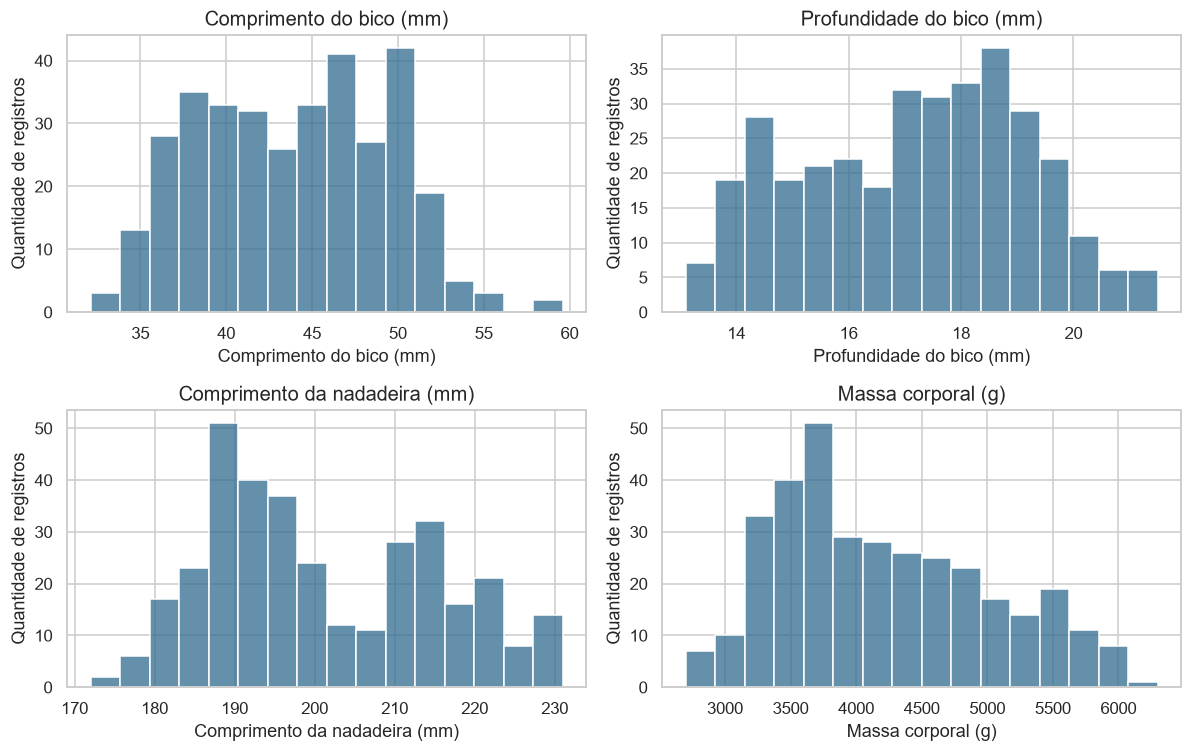

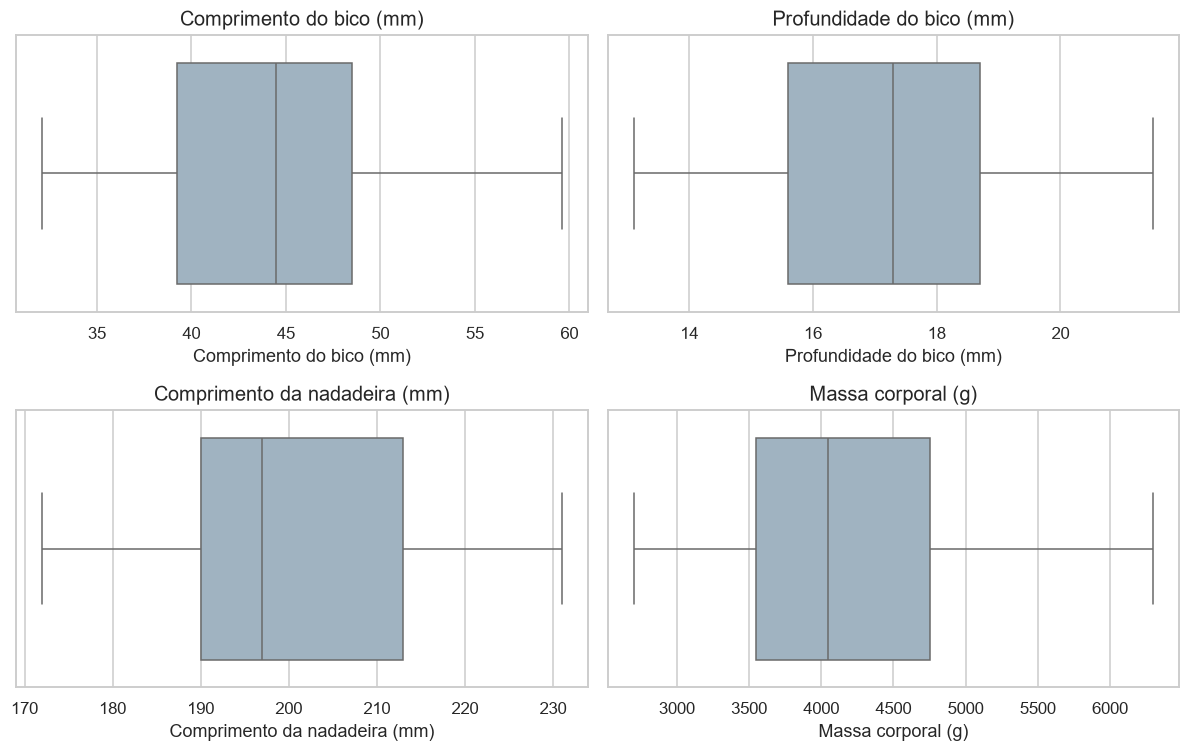

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for coluna, ax in zip(NUM, axes.flat):
    sns.histplot(data=df_antes, x=coluna, bins=16, color="#306b91", ax=ax)
    ax.set(xlabel=ROTULOS[coluna], ylabel="Quantidade de registros", title=ROTULOS[coluna])
mostrar_figura(fig, "01_histogramas.png")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for coluna, ax in zip(NUM, axes.flat):
    sns.boxplot(data=df_antes, x=coluna, color="#9ab4c7", ax=ax)
    ax.set(xlabel=ROTULOS[coluna], title=ROTULOS[coluna])
mostrar_figura(fig, "02_boxplots.png")

**Leitura:** a massa corporal observada varia de 2.700 a 6.300 g, com média de aproximadamente 4.201,8 g e mediana de 4.050 g. Os histogramas mostram a forma das distribuições e os boxplots resumem posição e dispersão. A base mistura três espécies, por isso a distribuição geral não deve ser interpretada como se todos os animais pertencessem ao mesmo grupo.

,quantidade,percentual
species,,
Adelie,152,44.19
Gentoo,124,36.05
Chinstrap,68,19.77


,quantidade,percentual
island,,
Biscoe,168,48.84
Dream,124,36.05
Torgersen,52,15.12


,quantidade,percentual
sex,,
male,168,48.84
female,165,47.97
não informado,11,3.2


,quantidade,percentual
year,,
2007,110,31.98
2008,114,33.14
2009,120,34.88


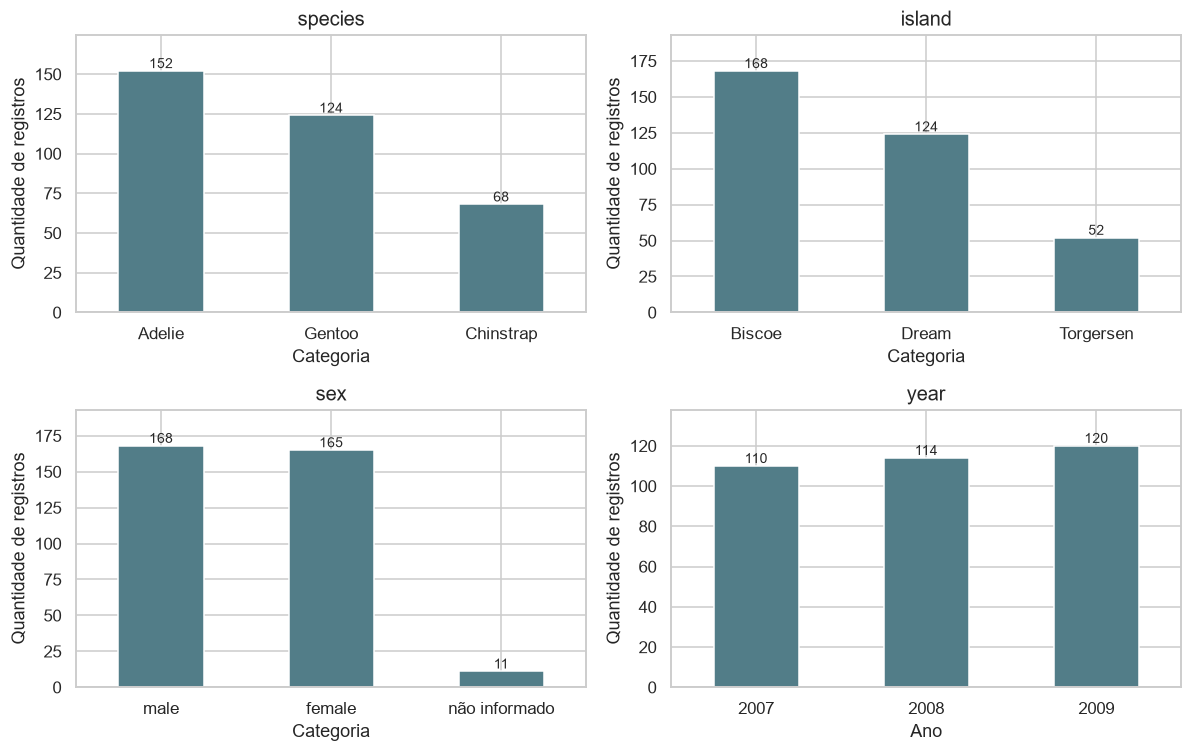

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for coluna, ax in zip(CAT + ["year"], axes.flat):
    serie = df_antes[coluna].astype("string").fillna("não informado")
    contagem = serie.value_counts()
    if coluna == "year":
        contagem = contagem.sort_index()
    display(pd.DataFrame({"quantidade": contagem, "percentual": contagem / len(serie) * 100}).round(2))
    contagem.plot.bar(ax=ax, color="#527d88", rot=0)
    ax.set(title=coluna, xlabel="Categoria" if coluna != "year" else "Ano", ylabel="Quantidade de registros")
    for barras in ax.containers:
        ax.bar_label(barras, fontsize=9)
    ax.margins(y=.15)
mostrar_figura(fig, "03_categorias.png")

**Conclusão:** na base original, Adelie tem 152 registros, Gentoo 124 e Chinstrap 68. As espécies têm tamanhos amostrais diferentes. Contagens absolutas e percentuais ajudam a evitar uma comparação que ignore essa diferença. Ano é mostrado como período de coleta, não como medida corporal.

### Normalidade e possíveis valores extremos

O teste de Shapiro–Wilk é complementar aos gráficos. Um p-valor menor que 0,05 indica evidência contra a normalidade; um valor maior não prova que a distribuição é normal. São verificações exploratórias, sem correção para múltiplos testes. Uma mistura de espécies pode produzir uma distribuição não normal.

In [7]:
normalidade = []
for c in NUM:
    w, p = stats.shapiro(df_antes[c].dropna())
    normalidade.append({"variavel": c, "W": w, "p_valor": p,
                        "evidencia_contra_normalidade_5pct": bool(p < .05)})
display(pd.DataFrame(normalidade).set_index("variavel"))

def resumo_iqr(dados):
    resultado = []
    for c in NUM:
        serie = dados[c].dropna()
        q1, q3 = serie.quantile([.25, .75])
        iqr = q3 - q1
        inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        resultado.append({"variavel": c, "limite_inferior": inferior,
                          "limite_superior": superior,
                          "sinalizados": int((~serie.between(inferior, superior)).sum())})
    return pd.DataFrame(resultado).set_index("variavel")

display(resumo_iqr(df_antes))
iqr_por_especie = pd.concat({esp: resumo_iqr(grupo) for esp, grupo in df_antes.groupby("species")},
                           names=["especie", "variavel"])
display(iqr_por_especie.loc[iqr_por_especie["sinalizados"] > 0])

,W,p_valor,evidencia_contra_normalidade_5pct
variavel,,,
bill_length_mm,0.974855,1.119730e-05,True
bill_depth_mm,0.972584,4.418820e-06,True
flipper_length_mm,0.951545,3.540136e-09,True
body_mass_g,0.959211,3.679039e-08,True


,limite_inferior,limite_superior,sinalizados
variavel,,,
bill_length_mm,25.3125,62.4125,0
bill_depth_mm,10.9500,23.3500,0
flipper_length_mm,155.5000,247.5000,0
body_mass_g,1750.0000,6550.0000,0


limite_inferior  limite_superior  sinalizados
especie   variavel                                                        
Adelie    bill_depth_mm               15.250           21.250            1
          flipper_length_mm          172.500          208.500            2
Chinstrap body_mass_g               2793.750         4643.750            2
Gentoo    bill_length_mm              38.925           55.925            1

**Normalidade:** os quatro p-valores ficaram abaixo de 0,05, trazendo evidência contra a normalidade das distribuições gerais. Isso reforça o cuidado com a mistura de espécies. A correlação de Pearson será usada como resumo descritivo de associação linear, sem assumir que esse diagnóstico, sozinho, determina se existe relação.

**Decisão sobre extremos:** a regra de 1,5 × IQR aplicada à base inteira não sinaliza extremos nas quatro medidas. Dentro das espécies, foram sinalizados valores em profundidade do bico e nadadeira de Adelie, massa de Chinstrap e comprimento do bico de Gentoo. Isso não comprova erro. Os valores observados serão mantidos: não há evidência suficiente para removê-los. Também não serão criadas ausências ou anomalias artificiais para demonstrar limpeza.

## 4. Tratamento de dados ausentes e anomalias

1. Preservar o CSV de origem sem alteração em `data/raw/penguins.csv`.
2. Excluir da base quantitativa as duas linhas sem medidas físicas. Imputar quatro medidas nesses registros criaria observações artificiais para a correlação.
3. Nas linhas restantes, preencher sexo ausente com `não informado`, sem tentar inferir o sexo pela massa ou espécie.
4. Manter as medidas observadas e as categorias. Não há duplicatas a remover.

Essa decisão elimina 2/344 registros (aproximadamente 0,58%). A proporção pequena não garante ausência de viés. A base de origem permite revisar a decisão depois.

In [8]:
removidos = df_antes.loc[df_antes[NUM].isna().any(axis=1)].copy()
df = df_antes.dropna(subset=NUM).copy()
df["sex"] = df["sex"].fillna("não informado")
df["year"] = df["year"].astype("int64")
df = df.reset_index(drop=True)

print("Linhas antes:", len(df_antes), "| depois:", len(df))
print("Células ausentes antes:", int(df_antes.isna().sum().sum()))
print("Células ausentes depois:", int(df.isna().sum().sum()))
display(removidos)
display(df["sex"].value_counts().rename("quantidade"))
assert df[NUM].notna().all().all()
assert (df[NUM] > 0).all().all()
assert len(df) + len(removidos) == len(df_original)
pd.testing.assert_frame_equal(df_original, df_antes)

Linhas antes: 344 | depois: 342
Células ausentes antes: 19
Células ausentes depois: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


sex
male             168
female           165
não informado      9
Name: quantidade, dtype: int64

## 5. Estatística descritiva — comparação antes e depois

A comparação numérica deve permanecer igual: as duas linhas removidas já não contribuíam para as estatísticas das medidas. A mudança é no total de registros e na identificação explícita do sexo não informado.

,n_antes,n_depois,media_antes,media_depois,desvio_padrao_antes,desvio_padrao_depois
bill_length_mm,342.0,342.0,43.922,43.922,5.460,5.460
bill_depth_mm,342.0,342.0,17.151,17.151,1.975,1.975
flipper_length_mm,342.0,342.0,200.915,200.915,14.062,14.062
body_mass_g,342.0,342.0,4201.754,4201.754,801.955,801.955


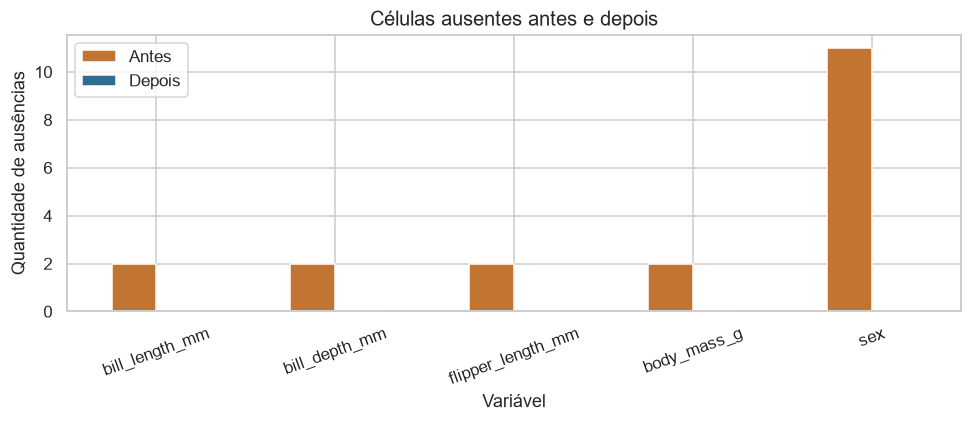

,Antes,Depois
species,,
Adelie,152,151
Gentoo,124,123
Chinstrap,68,68


In [9]:
resumo_depois = resumo_numerico(df)
comparacao = resumo_antes.add_suffix("_antes").join(resumo_depois.add_suffix("_depois"))
display(comparacao[["n_antes", "n_depois", "media_antes", "media_depois", "desvio_padrao_antes", "desvio_padrao_depois"]].round(3))
pd.testing.assert_frame_equal(resumo_antes, resumo_depois)

ausencias = pd.DataFrame({"Antes": df_antes.isna().sum(), "Depois": df.isna().sum()})
fig, ax = plt.subplots(figsize=(9, 4))
ausencias.loc[ausencias.sum(axis=1) > 0].plot.bar(ax=ax, color=["#c27432", "#306b91"], rot=20)
ax.set(title="Células ausentes antes e depois", xlabel="Variável", ylabel="Quantidade de ausências")
mostrar_figura(fig, "04_ausencias.png")
display(pd.DataFrame({"Antes": df_antes.species.value_counts(), "Depois": df.species.value_counts()}))

**Conclusão:** a base tratada possui 342 registros e nenhuma célula ausente. Nove registros permanecem com sexo `não informado`. As medidas físicas observadas não foram substituídas, portanto média, mediana e dispersão numérica foram preservadas. Adelie passou de 152 para 151 registros, e Gentoo de 124 para 123; Chinstrap permaneceu com 68.

## 6. Princípio relacional

### Quantitativa × quantitativa

Pearson resume associação linear, entre −1 e +1. A diagonal é 1 porque compara cada variável com ela mesma. Correlação não implica causalidade. Como comparação complementar, também calculamos Spearman, que trabalha com postos e resume associação monotônica. O ano da coleta não entra nessa matriz.

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.222,0.673,0.584
bill_depth_mm,-0.222,1.000,-0.523,-0.432
flipper_length_mm,0.673,-0.523,1.000,0.840
body_mass_g,0.584,-0.432,0.840,1.000


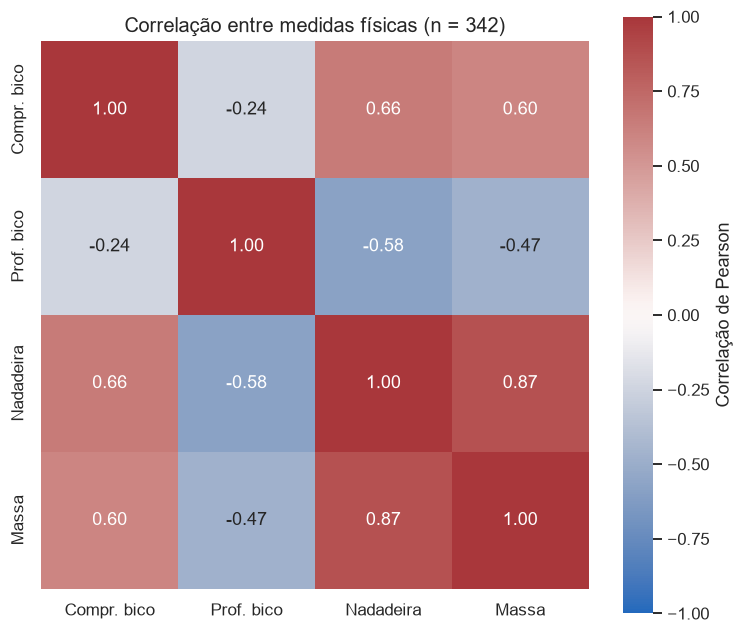

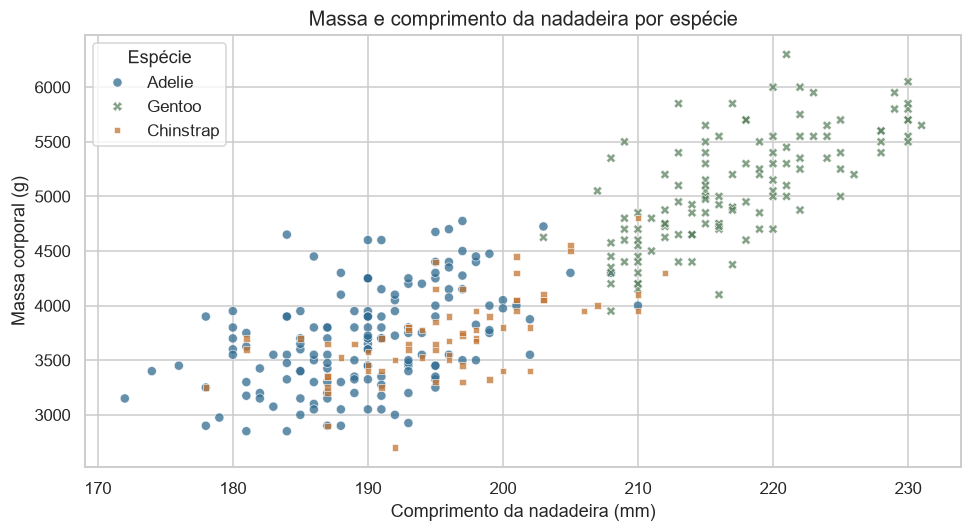

,n,pearson_nadadeira_massa
especie,,
Adelie,151,0.468
Chinstrap,68,0.642
Gentoo,123,0.703


In [10]:
corr_pearson = df[NUM].corr(method="pearson")
corr_spearman = df[NUM].corr(method="spearman")
display(corr_pearson.round(3))
display(corr_spearman.round(3))
curtos = {"bill_length_mm": "Compr. bico", "bill_depth_mm": "Prof. bico",
          "flipper_length_mm": "Nadadeira", "body_mass_g": "Massa"}
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_pearson.rename(index=curtos, columns=curtos), annot=True, fmt=".2f",
            cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"label": "Correlação de Pearson"}, ax=ax)
ax.set_title("Correlação entre medidas físicas (n = 342)")
mostrar_figura(fig, "05_correlacao.png")

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g", hue="species",
                style="species", palette=PALETA, alpha=.75, ax=ax)
ax.set(xlabel=ROTULOS["flipper_length_mm"], ylabel=ROTULOS["body_mass_g"],
       title="Massa e comprimento da nadadeira por espécie")
ax.legend(title="Espécie")
mostrar_figura(fig, "06_dispersao.png")

corr_grupos = pd.DataFrame([
    {"especie": esp, "n": len(g), "pearson_nadadeira_massa": g.flipper_length_mm.corr(g.body_mass_g)}
    for esp, g in df.groupby("species")
]).set_index("especie")
display(corr_grupos.round(3))

**Conclusão:** a correlação geral entre nadadeira e massa é aproximadamente 0,871. Dentro das espécies, ela é menor: cerca de 0,468 em Adelie, 0,642 em Chinstrap e 0,703 em Gentoo. Parte da relação geral acompanha diferenças entre espécies. Por isso, o filtro de espécie é útil no dashboard. Não se conclui que aumentar a nadadeira cause aumento de massa.

### Quantitativa × qualitativa

O boxplot compara a massa entre espécies sem esconder a dispersão de cada grupo.

,count,mean,median,std,min,max
species,,,,,,
Adelie,151,3700.66,3700.0,458.57,2850.0,4775.0
Chinstrap,68,3733.09,3700.0,384.34,2700.0,4800.0
Gentoo,123,5076.02,5000.0,504.12,3950.0,6300.0


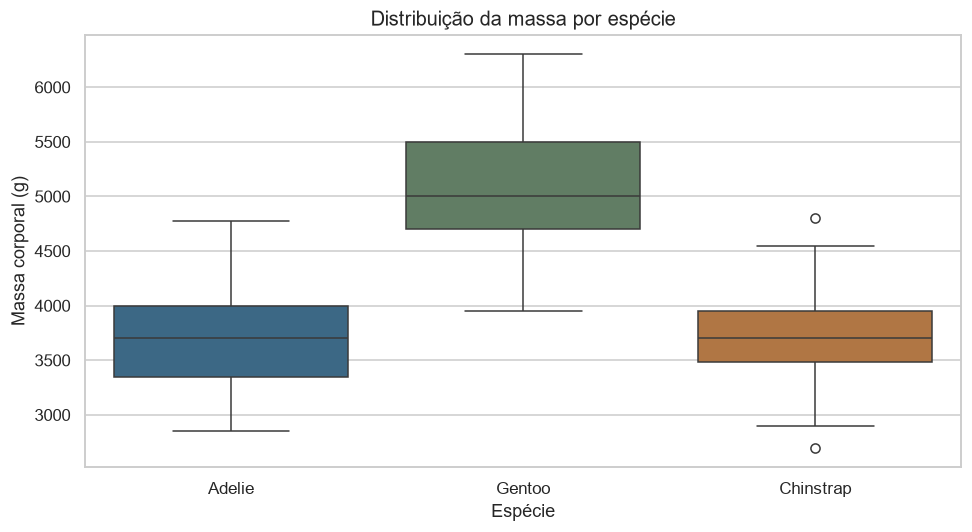

In [11]:
display(df.groupby("species")["body_mass_g"].agg(["count", "mean", "median", "std", "min", "max"]).round(2))
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="species", y="body_mass_g", hue="species", palette=PALETA, legend=False, ax=ax)
ax.set(xlabel="Espécie", ylabel="Massa corporal (g)", title="Distribuição da massa por espécie")
mostrar_figura(fig, "07_massa_especie.png")

**Conclusão:** Gentoo tem maior massa média nesta amostra (aproximadamente 5.076 g). Adelie e Chinstrap apresentam médias próximas, cerca de 3.701 g e 3.733 g. Isso é uma comparação descritiva da amostra, não uma estimativa garantida para toda a população de pinguins.

### Qualitativa × qualitativa

As tabelas abaixo comparam espécie e ilha. A porcentagem é calculada dentro de cada espécie, deixando claro o denominador.

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


island,Biscoe,Dream,Torgersen
species,,,
Adelie,29.1,37.1,33.8
Chinstrap,0.0,100.0,0.0
Gentoo,100.0,0.0,0.0


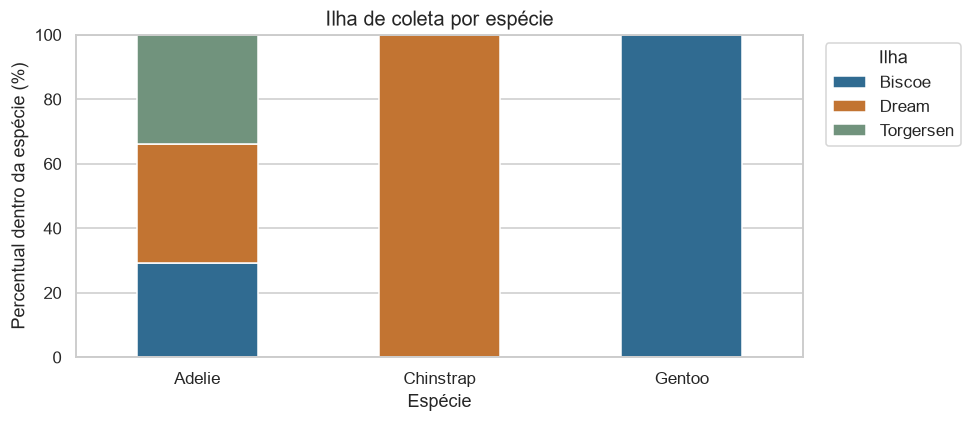

In [12]:
frequencia = pd.crosstab(df.species, df.island)
proporcao = pd.crosstab(df.species, df.island, normalize="index") * 100
display(frequencia)
display(proporcao.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
proporcao.plot.bar(stacked=True, ax=ax, color=["#306b91", "#c27432", "#71937d"], rot=0)
ax.set(xlabel="Espécie", ylabel="Percentual dentro da espécie (%)", title="Ilha de coleta por espécie", ylim=(0, 100))
ax.legend(title="Ilha", bbox_to_anchor=(1.02, 1), loc="upper left")
mostrar_figura(fig, "08_especie_ilha.png")

**Conclusão:** nesta amostra, Chinstrap aparece somente em Dream, e Gentoo somente em Biscoe. Adelie aparece nas três ilhas. Isso limita a separação dos efeitos de espécie e ilha: diferenças entre ilhas não podem ser atribuídas diretamente ao ambiente sem considerar quais espécies foram amostradas.

**Testes de associação:** a comparação foi mantida descritiva, como no notebook anterior, em que testes inferenciais eram opcionais. O teste de normalidade acima é apenas diagnóstico exploratório.

## 7. Análise multivariada

Combinamos nadadeira, massa, espécie e sexo. Sexo não informado aparece explicitamente como grupo e não é inferido. O gráfico ajuda a observar sobreposição e diferenças entre grupos, sem construir um classificador.

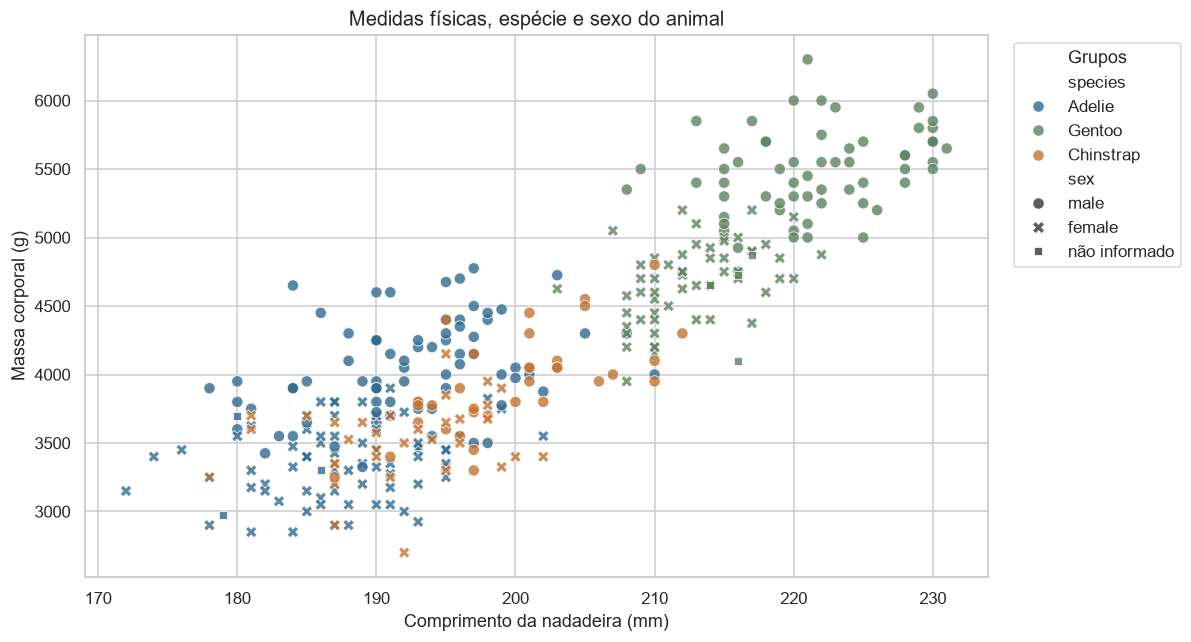

count     mean  median
species   sex                                  
Adelie    female            73  3368.84  3400.0
          male              73  4043.49  4000.0
          não informado      5  3540.00  3475.0
Chinstrap female            34  3527.21  3550.0
          male              34  3938.97  3950.0
Gentoo    female            58  4679.74  4700.0
          male              61  5484.84  5500.0
          não informado      4  4587.50  4687.5

In [13]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g", hue="species", style="sex",
                palette=PALETA, s=55, alpha=.8, ax=ax)
ax.set(xlabel=ROTULOS["flipper_length_mm"], ylabel=ROTULOS["body_mass_g"],
       title="Medidas físicas, espécie e sexo do animal")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Grupos")
mostrar_figura(fig, "09_multivariada.png")
display(df.groupby(["species", "sex"])["body_mass_g"].agg(["count", "mean", "median"]).round(2))

**Leitura:** o gráfico deve ser interpretado junto da tabela de tamanho dos grupos. Há sobreposição entre registros, e os grupos de sexo não informado são pequenos. As diferenças são observacionais; não há experimento nem amostragem de toda a Antártida.

### Representatividade e fairness

Não há pessoas, atributos humanos protegidos ou decisões automatizadas sobre indivíduos nesta atividade. Portanto, métricas de fairness de classificação humana não se aplicam. Ainda assim, a representatividade importa: as espécies têm contagens diferentes, a distribuição por ilha não é uniforme e a coleta ocorreu em três anos. Esses limites restringem a generalização.

## 8. Conclusão geral

A base contém medidas físicas adequadas para a atividade de correlação e distribuição. Após o tratamento, ficaram 342 registros. Foram retiradas apenas duas linhas sem medidas e os nove casos restantes de sexo ausente foram identificados como `não informado`. As medidas existentes foram preservadas, assim como os valores sinalizados pela análise de IQR por espécie.

A associação entre comprimento da nadadeira e massa corporal é positiva e forte na amostra total, mas diminui quando as espécies são analisadas separadamente. Gentoo apresenta maior massa média. A composição por espécie e ilha precisa ser considerada ao interpretar os gráficos.

O dashboard terá seleção de medidas, filtro de espécie e slider de massa corporal. Assim, será possível verificar como os filtros alteram a correlação e a distribuição, sem tratar categorias como números artificiais.

## 9. Exportação para o dashboard e verificação

O bruto continua em `data/raw/penguins.csv`. O tratado é salvo em `data/clean/penguins.csv`; este é o arquivo que o esqueleto do dashboard lê. Ambos os CSVs são versionáveis. O notebook inclui a URL e o hash para recuperar e conferir a fonte original.

In [14]:
df.to_csv(CLEAN, index=False, encoding="utf-8")
reaberto = pd.read_csv(CLEAN)
pd.testing.assert_frame_equal(reaberto, df, check_dtype=False)
resumo_depois.to_csv(ROOT / "reports/resumo_numerico_penguins.csv", encoding="utf-8")
corr_pearson.to_csv(ROOT / "reports/correlacao_penguins.csv", encoding="utf-8")
auditoria = {
    "fonte": URL, "sha256_bruto": sha_atual,
    "linhas_originais": len(df_original), "linhas_tratadas": len(df),
    "linhas_excluidas_sem_medidas": len(removidos),
    "sexo_nao_informado": int(df.sex.eq("não informado").sum()),
    "ausentes_antes": df_antes.isna().sum().astype(int).to_dict(),
    "ausentes_depois": df.isna().sum().astype(int).to_dict(),
    "medidas": NUM, "correlacao_nadadeira_massa": float(corr_pearson.loc["flipper_length_mm", "body_mass_g"]),
    "python": sys.version.split()[0],
    "bibliotecas": {p: metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "seaborn", "scipy"]},
}
(ROOT / "reports/verificacao_penguins.json").write_text(json.dumps(auditoria, ensure_ascii=False, indent=2), encoding="utf-8")
print("Exportado e conferido:", CLEAN.relative_to(ROOT))
print("Dimensão:", reaberto.shape)
print("Medidas disponíveis:", NUM)

Exportado e conferido: data\clean\penguins.csv
Dimensão: (342, 8)
Medidas disponíveis: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


## 10. Rascunho do Dashboard 1

- **Filtros no topo:** multisseleção das quatro medidas quantitativas, filtro de espécie e slider de intervalo da massa corporal (2.700–6.300 g na base tratada completa).
- **Correlação:** espaço reservado para heatmap de Pearson entre as medidas selecionadas. Exigir pelo menos duas medidas e dados com variação.
- **Distribuição:** seletor de uma medida e espaço reservado para histograma; opção de distinguir as espécies.
- **Contexto:** mostrar a quantidade de registros após os filtros e as unidades das medidas.
- **Estado vazio:** informar quando os filtros não deixam registros, sem desenhar um gráfico enganoso.

Na Aula 21, a implementação é o esqueleto e os widgets presentes em `app.py`. Os gráficos do dashboard ficam para a próxima aula. Os gráficos acima pertencem à EDA.

Para o futuro Dashboard 2, a mesma base permite indicadores como número de registros filtrados, massa média, mediana da massa e proporção por espécie. A definição final depende da próxima aula.